# MT Chiller 1 – Performance Analysis

Plots for the meeting brief, using the 5 history sheets in `20261016_benny - Copy.xlsx` (MT CH01, 1-minute data, five 2-day windows).

1. Chilled water temperatures and ΔT
2. kW/RT against cooling load
3. Condenser water supply temperature against kW/RT
4. Readings against the alarm limits (sheet 4)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FILE = r"D:\XenOptimization\20261016_benny - Copy.xlsx"
PREFIX = "C10A1_1_C101C_MTCHW_"
RT_KW = 3.517  # 1 refrigeration ton = 3.517 kW thermal

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Load the data

In [2]:
frames = []
for i in range(1, 6):
    d = pd.read_excel(FILE, sheet_name=f"2.Hist Value{i}")
    d["Window"] = pd.to_datetime(d["DateTime"]).min().strftime("%b %Y")
    frames.append(d)

df = pd.concat(frames, ignore_index=True)
df["DateTime"] = pd.to_datetime(df["DateTime"])
df.columns = [c.replace(PREFIX, "") for c in df.columns]

num_cols = df.columns.difference(["DateTime", "Window"])
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")

# Derived values
df["CHW_dT"] = df["CH01_TIT4.PV"] - df["CH01_TIT3.PV"]   # chilled water return - supply, °C
df["CW_dT"]  = df["CH01_TIT2.PV"] - df["CH01_TIT1.PV"]   # condenser water return - supply, °C
df["Load_RT"] = df["CH01_CL1.PV"] / RT_KW                 # cooling load, RT
df["kW_RT"]   = df["CH01_EF.PV2"]                          # kW/RT (estimated from motor current)

windows = list(df["Window"].unique())
print(df.shape)
df.groupby("Window")[["Load_RT", "kW_RT", "CHW_dT", "CH01_TIT1.PV"]].mean().round(2)

(14400, 39)


,Load_RT,kW_RT,CHW_dT,CH01_TIT1.PV
Window,,,,
Aug 2024,2274.94,0.37,5.39,29.20
Aug 2025,2355.25,0.38,5.95,29.97
Feb 2024,2184.82,0.38,5.21,30.02
Feb 2025,2186.99,0.36,5.55,28.11
Feb 2026,2260.82,0.39,5.66,29.64


## 1. Chilled water temperatures and ΔT

Supply is held at about 12.8 °C in every window, so the chilled water setpoint never changed in this sample.

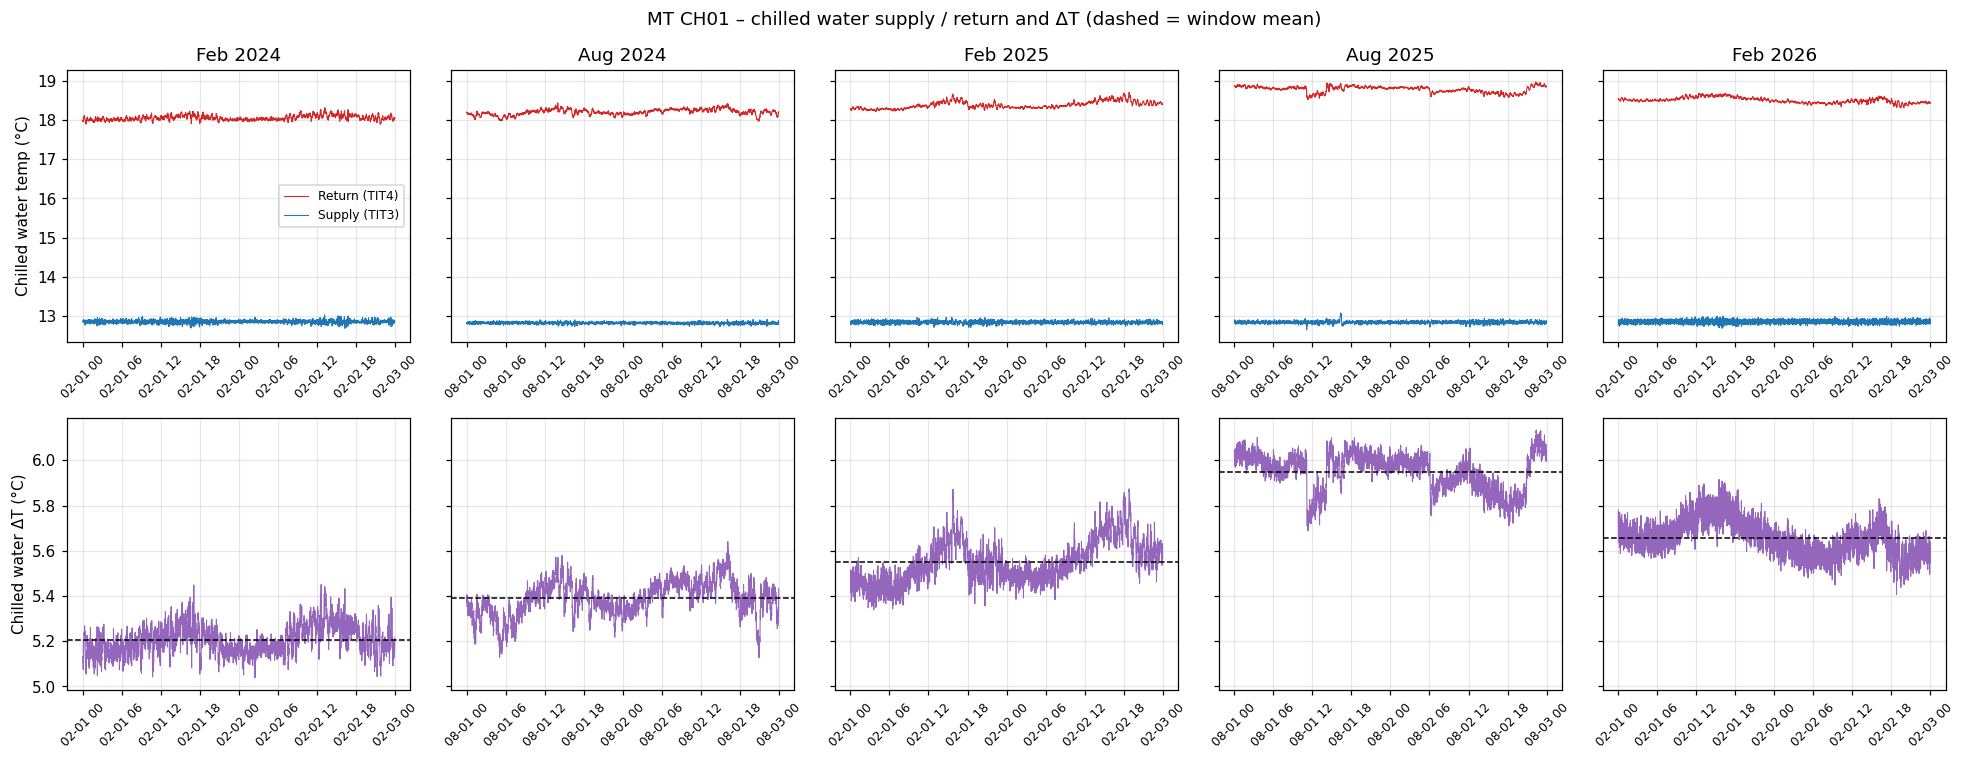

In [3]:
fig, axes = plt.subplots(2, len(windows), figsize=(18, 7), sharey="row")
for ax_t, ax_d, w in zip(axes[0], axes[1], windows):
    d = df[df["Window"] == w]
    ax_t.plot(d["DateTime"], d["CH01_TIT4.PV"], lw=0.7, color="tab:red", label="Return (TIT4)")
    ax_t.plot(d["DateTime"], d["CH01_TIT3.PV"], lw=0.7, color="tab:blue", label="Supply (TIT3)")
    ax_t.set_title(w)
    ax_d.plot(d["DateTime"], d["CHW_dT"], lw=0.7, color="tab:purple")
    ax_d.axhline(d["CHW_dT"].mean(), color="black", ls="--", lw=1)
    for ax in (ax_t, ax_d):
        ax.tick_params(axis="x", rotation=45, labelsize=8)
axes[0, 0].set_ylabel("Chilled water temp (°C)")
axes[1, 0].set_ylabel("Chilled water ΔT (°C)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("MT CH01 – chilled water supply / return and ΔT (dashed = window mean)")
fig.tight_layout()
plt.show()

## 2. kW/RT against cooling load

`EF.PV2` is used as kW/RT. It is estimated from motor current, not from a power meter.

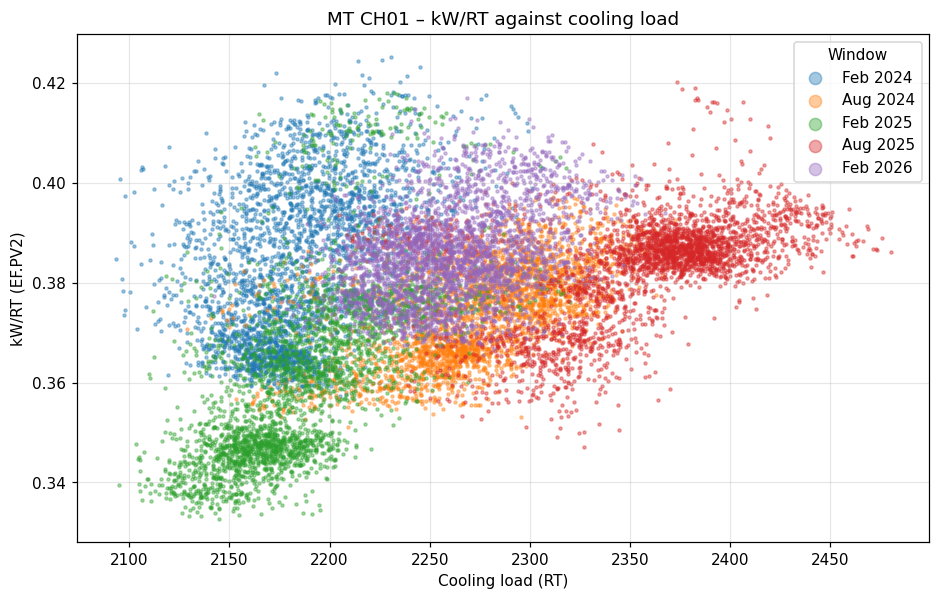

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
for w in windows:
    d = df[df["Window"] == w]
    ax.scatter(d["Load_RT"], d["kW_RT"], s=4, alpha=0.4, label=w)
ax.set_xlabel("Cooling load (RT)")
ax.set_ylabel("kW/RT (EF.PV2)")
ax.set_title("MT CH01 – kW/RT against cooling load")
ax.legend(markerscale=4, title="Window")
plt.show()

## 3. Condenser water supply temperature against kW/RT

Cooler condenser water normally lowers kW/RT. This slope is where cooling tower optimisation saves energy.

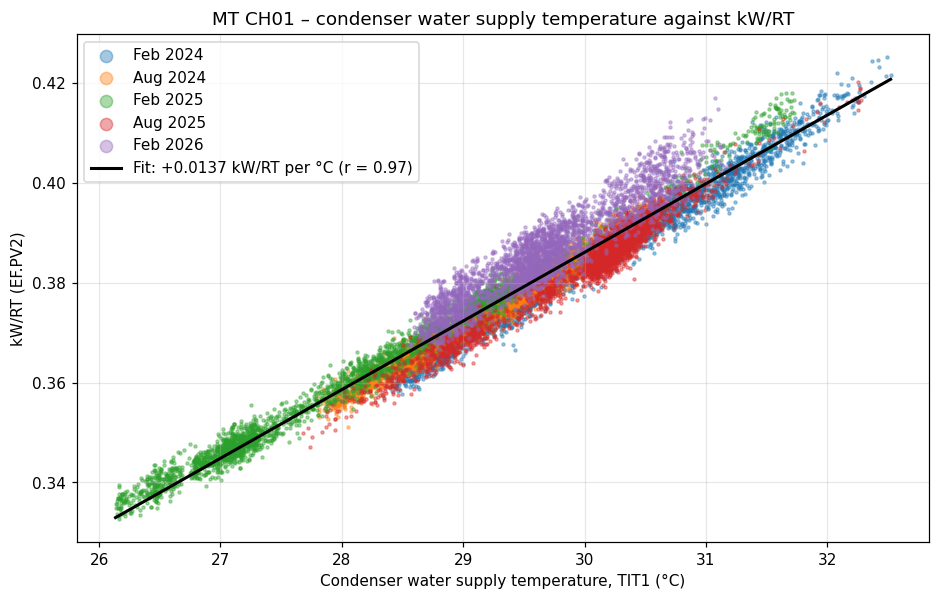

Each 1 °C drop in condenser water supply changes kW/RT by -0.0137 (-3.6% of the mean 0.378).
Note: correlation only. Load and weather also move with TIT1.


In [5]:
d = df.dropna(subset=["CH01_TIT1.PV", "kW_RT"])
slope, intercept = np.polyfit(d["CH01_TIT1.PV"], d["kW_RT"], 1)
r = d["CH01_TIT1.PV"].corr(d["kW_RT"])

fig, ax = plt.subplots(figsize=(10, 6))
for w in windows:
    s = d[d["Window"] == w]
    ax.scatter(s["CH01_TIT1.PV"], s["kW_RT"], s=4, alpha=0.4, label=w)
x = np.linspace(d["CH01_TIT1.PV"].min(), d["CH01_TIT1.PV"].max(), 50)
ax.plot(x, slope * x + intercept, color="black", lw=2,
        label=f"Fit: {slope:+.4f} kW/RT per °C (r = {r:.2f})")
ax.set_xlabel("Condenser water supply temperature, TIT1 (°C)")
ax.set_ylabel("kW/RT (EF.PV2)")
ax.set_title("MT CH01 – condenser water supply temperature against kW/RT")
ax.legend(markerscale=4)
plt.show()

print(f"Each 1 °C drop in condenser water supply changes kW/RT by {-slope:+.4f} "
      f"({-slope / d['kW_RT'].mean() * 100:+.1f}% of the mean {d['kW_RT'].mean():.3f}).")
print("Note: correlation only. Load and weather also move with TIT1.")

## 4. Readings against the alarm limits (sheet 4)

Sheet 4 holds Hi / HiHi / Lo / LoLo limits per chiller. The client calls these the safe range.

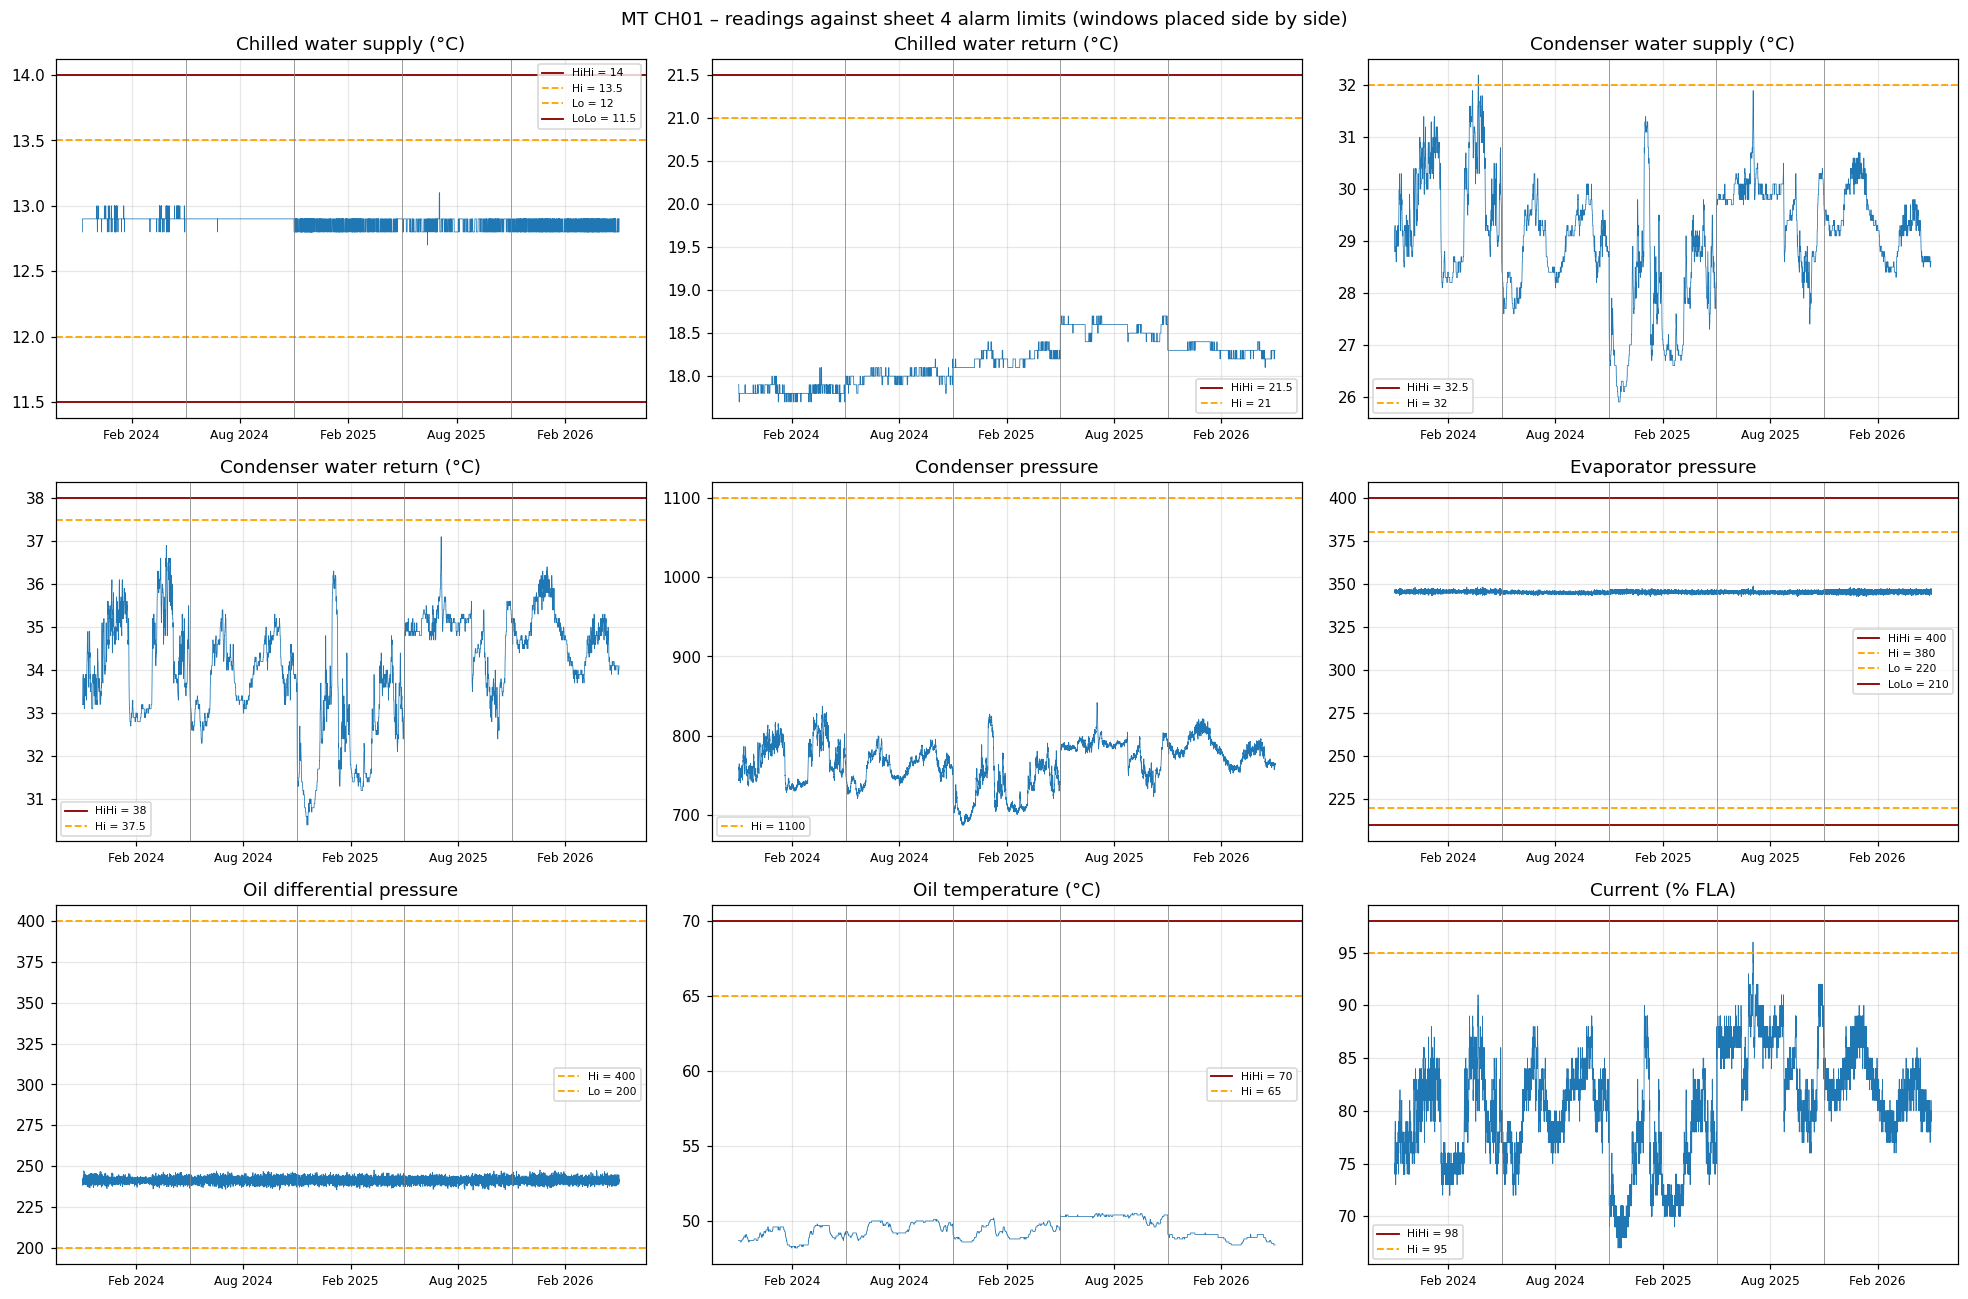

,Min,Max,HiHi,Hi,Lo,LoLo
Parameter,,,,,,
Chilled water supply (°C),12.7,13.1,14.0,13.5,12.0,11.5
Chilled water return (°C),17.7,18.7,21.5,21.0,NaN,NaN
Condenser water supply (°C),25.9,32.2,32.5,32.0,NaN,NaN
Condenser water return (°C),30.4,37.1,38.0,37.5,NaN,NaN
Condenser pressure,687.4,841.8,NaN,1100.0,NaN,NaN
Evaporator pressure,342.7,348.9,400.0,380.0,220.0,210.0
Oil differential pressure,235.4,247.7,NaN,400.0,200.0,NaN
Oil temperature (°C),48.2,50.5,70.0,65.0,NaN,NaN
Current (% FLA),67.0,96.0,98.0,95.0,NaN,NaN


In [6]:
raw = pd.read_excel(FILE, sheet_name="4", header=None)

# Each block starts with a ':Tagname' header row; find the row for MT CH01
limits = None
header = None
for _, row in raw.iterrows():
    if row[0] == ":Tagname":
        header = row.tolist()
    elif header is not None and row[0] == "C10A1_1_C101C_MTCHW_CH01":
        limits = pd.Series(row.values, index=header)
        break

params = {
    "CWSupplyTempS":   "Chilled water supply (°C)",
    "CWReturnTempS":   "Chilled water return (°C)",
    "CondSupplyTempS": "Condenser water supply (°C)",
    "CondReturnTempS": "Condenser water return (°C)",
    "CondPressS":      "Condenser pressure",
    "EvapPressS":      "Evaporator pressure",
    "OilDPS":          "Oil differential pressure",
    "OilTempS":        "Oil temperature (°C)",
    "CurrentS":        "Current (% FLA)",
}
styles = {"HiHi": ("darkred", "-"), "Hi": ("orange", "--"), "Lo": ("orange", "--"), "LoLo": ("darkred", "-")}

summary = []
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, (p, label) in zip(axes.flat, params.items()):
    s = df[f"CH01.{p}"]
    ax.plot(range(len(s)), s, lw=0.5, color="tab:blue")
    row = {"Parameter": label, "Min": s.min(), "Max": s.max()}
    for lvl, (col, ls) in styles.items():
        v = pd.to_numeric(limits.get(f"{p}.{lvl}.Limit"), errors="coerce")
        row[lvl] = v
        if pd.notna(v):
            ax.axhline(v, color=col, ls=ls, lw=1.2, label=f"{lvl} = {v:g}")
    ax.set_title(label)
    ax.set_xticks([i * 2880 + 1440 for i in range(len(windows))], windows, fontsize=8)
    for i in range(1, len(windows)):
        ax.axvline(i * 2880, color="grey", lw=0.5)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=7, loc="best")
    summary.append(row)
fig.suptitle("MT CH01 – readings against sheet 4 alarm limits (windows placed side by side)")
fig.tight_layout()
plt.show()

pd.DataFrame(summary).set_index("Parameter").round(2)